In [5]:
import numpy as np

import matplotlib.pyplot as plt
import scienceplots  # noqa: F401
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
plt.style.use("science")
set_matplotlib_formats("svg")
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.titlesize": 19,
})

REGION_COLORS = {
    "empty": "#d9d9d9",
    "empty_and_star": "#c84c09",
    "star": "#1f4e79",
    "complete": "#3a7d44",
}

In [6]:
# Nash network
def nash_f1(x, n):
    return 1 / (x - x**2), r"$\frac{1}{\delta-\delta^2}$"


def nash_f2(x, n):
    return 1 / x, r"$\frac{1}{\delta}$"


def nash_f3(x, n):
    return 1 / (x + (n - 1) * x**2), r"$\frac{1}{\delta+(n-1)\delta^2}$"


# Efficient network
def eff_f1(x, n):
    return 1 / (2 * (x - x**2)), r"$\frac{1}{2(\delta-\delta^2)}$"


def eff_f2(x, n):
    return 1 / (2 * x + (n - 2) * x**2), r"$\frac{1}{2\delta+(n-2)\delta^2}$"

In [7]:
n = 10
eps = 1e-3

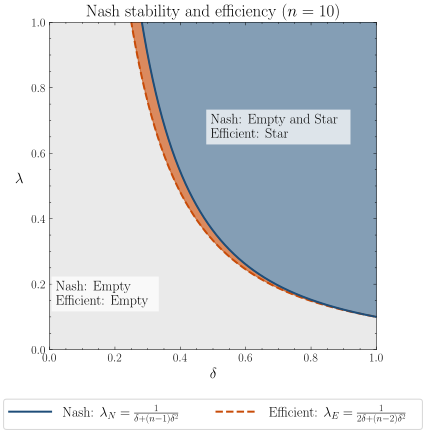

In [8]:
joint_x = np.linspace(eps, 1, 1000)
lambda_nash, _ = nash_f3(joint_x, n)
lambda_eff, _ = eff_f2(joint_x, n)
lambda_max = 1.0

nash_visible = np.minimum(lambda_nash, lambda_max)
eff_visible = np.minimum(lambda_eff, lambda_max)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")

ax.fill_between(
    joint_x,
    0,
    eff_visible,
    color=REGION_COLORS["empty"],
    alpha=0.55,
)
ax.fill_between(
    joint_x,
    eff_visible,
    nash_visible,
    where=nash_visible > eff_visible,
    color=REGION_COLORS["empty_and_star"],
    alpha=0.65,
    interpolate=True,
)
ax.fill_between(
    joint_x,
    nash_visible,
    lambda_max,
    where=nash_visible < lambda_max,
    color=REGION_COLORS["star"],
    alpha=0.55,
    interpolate=True,
)

(eff_line,) = ax.plot(
    joint_x,
    lambda_eff,
    color=REGION_COLORS["empty_and_star"],
    linestyle="--",
    linewidth=2,
    label=r"Efficient: $\lambda_E=\frac{1}{2\delta+(n-2)\delta^2}$",
)
(nash_line,) = ax.plot(
    joint_x,
    lambda_nash,
    color=REGION_COLORS["star"],
    linewidth=2,
    label=r"Nash: $\lambda_N=\frac{1}{\delta+(n-1)\delta^2}$",
)
ax.legend(
    handles=[nash_line, eff_line],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    handlelength=3,
    fontsize=plt.rcParams["font.size"],
    frameon=True,
)

label_box = {"facecolor": "white", "edgecolor": "none", "alpha": 0.72}
ax.text(
    0.17,
    0.17,
    "Nash: Empty\nEfficient: Empty",
    ha="center",
    multialignment="left",
    va="center",
    bbox=label_box,
)
ax.text(
    0.70,
    0.68,
    "Nash: Empty and Star\nEfficient: Star",
    ha="center",
    multialignment="left",
    va="center",
    bbox=label_box,
)

mismatch_x = 0.17
mismatch_y = 0.5 * (
    np.interp(mismatch_x, joint_x, lambda_eff)
    + np.interp(mismatch_x, joint_x, lambda_nash)
)
ax.annotate(
    "Nash: Empty\nEfficient: Star",
    xy=(mismatch_x, mismatch_y),
    xytext=(0.37, 0.45),
    ha="center",
    multialignment="left",
    va="center",
    bbox={
        "facecolor": REGION_COLORS["empty_and_star"],
        "edgecolor": "black",
        "alpha": 0.88,
    },
    arrowprops={"arrowstyle": "->", "color": "black", "linewidth": 1},
)

ax.set(
    xlim=(0, 1),
    ylim=(0, lambda_max),
    xlabel=r"$\delta$",
    ylabel=r"$\lambda$",
    title=f"Nash stability and efficiency ($n={n}$)",
)
unit_ticks = np.linspace(0, 1, 6)
ax.set_xticks(unit_ticks)
ax.set_yticks(unit_ticks)
ax.set_ylabel(r"$\lambda$", rotation=0, labelpad=12)
ax.set_aspect("equal", adjustable="box")
plt.show()